In [1]:
import re
import os
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from torch_geometric.data import HeteroData
from torch_geometric.loader import DataLoader
from torch_geometric.nn import HeteroConv, SAGEConv

import matplotlib.pyplot as plt


# Repro + device

def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# CONFIG: file + columns
         
EXCEL_PATH_A = "Dataset A — ASU.xlsx"   
HEADER_ROW_A = 1

TARGET_COL  = "FCXN_VALUE (N/mm²)"
CASTING_COL = "Casting Strength (MPa)"

PRINTING_COLS = [
    "nozzle travel velocity (mm/s)",
    "No. adjacent filaments",
    "layer height (mm)",
    "No. Layers",
    "vertical layer interval time (s)",
    "time mixing to print (s)",
    "Nozzle Type (1=circular; 2 =rectangular)",
    "nozzle diameter (mm)",
    "nozzle length (mm)",
    "nozzle width (mm)",
]

SAMPLE_COLS = [
    "age (day)",
    "Sample Location (1=top;2=middle;3=bottom;4=unknow)",
    "extraction method (1=sawing; 2=core drilling; 3=waterjet)",
    "Direction (1=u,2=v,3=w)",
    "Sample shape (1= cube; 2= cylinder)",
    "sample density (kg/m³)",
]


MIDDLE_MIDDLE_EDGES = [
    ("middle", 0, 1, True),  
    ("middle", 1, 2, True), 
]

MIDDLE_TO_OUTPUT_EDGES = [
    ("printing", "to_out", "output", False),
    ("sample",   "to_out", "output", False),
    ("casting",  "to_out", "output", False),
]

EVAL_TEST_EVERY_EPOCH = False  

# Load + clean Excel headers (A = ASU adaptation and test)

def clean_col(c):
    c = str(c)
    c = c.replace("\xa0", " ").replace("Â", "")
    c = re.sub(r"\s+", " ", c).strip()
    return c

def load_clean_excel(path, header_row):
    df = pd.read_excel(path, header=header_row)
    df.columns = [clean_col(c) for c in df.columns]
    return df

df_A = load_clean_excel(EXCEL_PATH_A, HEADER_ROW_A)

# normalize column names lists too
TARGET_COL  = clean_col(TARGET_COL)
CASTING_COL = clean_col(CASTING_COL)
PRINTING_COLS = [clean_col(c) for c in PRINTING_COLS]
SAMPLE_COLS   = [clean_col(c) for c in SAMPLE_COLS]

needed = [TARGET_COL, CASTING_COL] + PRINTING_COLS + SAMPLE_COLS

for name, d in [("Dataset A", df_A)]:
    missing = [c for c in needed if c not in d.columns]
    if missing:
        raise ValueError(f"Missing columns in {name} (after cleaning):\n" + "\n".join(missing))

def to_numeric_and_drop(df):
    for c in (PRINTING_COLS + SAMPLE_COLS + [CASTING_COL, TARGET_COL]):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df.dropna(subset=PRINTING_COLS + SAMPLE_COLS + [CASTING_COL, TARGET_COL]).reset_index(drop=True)

df_A = to_numeric_and_drop(df_A)

print("Rows kept | ASU Data:", len(df_A))


# Split: adapt the pretrained model with 20% of ASU; test on untouched 80%.

idx_A = np.arange(len(df_A))
A_train_idx, A_test_idx = train_test_split(idx_A, test_size=0.8, random_state=42)
A_fit_idx, A_val_idx = train_test_split(A_train_idx, test_size=0.20, random_state=42)

print("ASU splits | update pool (20%):", len(A_train_idx),
      " internal train:", len(A_fit_idx), " internal val:", len(A_val_idx),
      " held-out test (80%):", len(A_test_idx))


# Load the EXACT preprocessing and pretrained weights saved by Notebook 1 (Step 1).

X_cols = PRINTING_COLS + SAMPLE_COLS + [CASTING_COL]
checkpoint_path = "trained_models/group_node_PGNN_pretrained.pt"
scalers_path = "trained_models/group_node_PGNN_scalers.joblib"

for path in (checkpoint_path, scalers_path):
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing {path}. Run Notebook 1 first and keep its trained_models folder here."
        )

pretrained_checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
saved_scalers = joblib.load(scalers_path)

if list(pretrained_checkpoint["input_columns"]) != X_cols:
    raise ValueError("Notebook 1 model has different input columns/order.")
if list(saved_scalers["input_columns"]) != X_cols:
    raise ValueError("Notebook 1 scalers have different input columns/order.")

x_scaler = saved_scalers["x_scaler"]
y_scaler = saved_scalers["y_scaler"]
print("Loaded Notebook 1's pretrained checkpoint and original scalers.")

y_mean = float(y_scaler.mean_[0])
y_std  = float(y_scaler.scale_[0])

def scale_y(y_raw: float) -> float:
    return (y_raw - y_mean) / (y_std + 1e-12)

def inverse_scale_y(y_scaled_t: torch.Tensor) -> torch.Tensor:
    return y_scaled_t * (y_std + 1e-12) + y_mean

# Graph builder (1 row = 1 graph) - dataframe-aware

def get_scaled_row(df_src: pd.DataFrame, i: int):
    raw_x = df_src.loc[i, X_cols].values.astype(float)
    xs    = x_scaler.transform([raw_x])[0]

    p = xs[:len(PRINTING_COLS)]
    s = xs[len(PRINTING_COLS):len(PRINTING_COLS)+len(SAMPLE_COLS)]
    c = xs[-1]

    y_raw = float(df_src.loc[i, TARGET_COL])
    y_s   = scale_y(y_raw)
    return p, s, c, y_raw, y_s


def build_graph(df_src: pd.DataFrame, i: int) -> HeteroData:
    pvec, svec, cval, y_raw, y_s = get_scaled_row(df_src, i)
    data = HeteroData()

    data["printing"].x = torch.tensor(pvec, dtype=torch.float32).view(1, -1)
    data["sample"].x   = torch.tensor(svec, dtype=torch.float32).view(1, -1)
    data["casting"].x  = torch.tensor([[cval]], dtype=torch.float32)

    data["output"].x = torch.zeros((1, 1), dtype=torch.float32)

    # targets
    data["output"].y     = torch.tensor([y_s], dtype=torch.float32)      
    data["output"].y_raw = torch.tensor([y_raw], dtype=torch.float32)    

    def set_edge(src_type, rel, dst_type, pairs):
        if not pairs:
            return
        edge_index = torch.tensor(pairs, dtype=torch.long).t().contiguous()
        data[(src_type, rel, dst_type)].edge_index = edge_index

    def set_edge_bidir(src_type, rel, dst_type, pairs):
        set_edge(src_type, rel, dst_type, pairs)
        rev_pairs = [(b, a) for (a, b) in pairs]
        set_edge(dst_type, rel + "_rev", src_type, rev_pairs)

    # Middle↔Middle
    middle_map = {0: "printing", 1: "sample", 2: "casting"}
    for _, a, b, bi in MIDDLE_MIDDLE_EDGES:
        src = middle_map[a]
        dst = middle_map[b]
        rel = f"m_{a}_{b}"
        if bi:
            set_edge_bidir(src, rel, dst, [(0, 0)])
        else:
            set_edge(src, rel, dst, [(0, 0)])

    # Middle→Output
    for src, rel, dst, bi in MIDDLE_TO_OUTPUT_EDGES:
        if bi:
            set_edge_bidir(src, rel, dst, [(0, 0)])
        else:
            set_edge(src, rel, dst, [(0, 0)])

    return data


def build_dataset(df_src: pd.DataFrame, idxs):
    return [build_graph(df_src, int(i)) for i in idxs]


train_set = build_dataset(df_A, A_fit_idx)
val_set   = build_dataset(df_A, A_val_idx)
test_set  = build_dataset(df_A, A_test_idx)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_set, batch_size=128, shuffle=False)

print("Graphs | ASU update/train:", len(train_set),
      " val(ASU update):", len(val_set), " test(ASU held out):", len(test_set))



# Model: HeteroConv + SAGEConv, predict at output (scaled)

class HeteroHierGNN(nn.Module):
    def __init__(self, hidden_dim=256, num_layers=2, dropout=0.10):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.dropout = dropout

        self.lin_in = nn.ModuleDict({
            "printing": nn.Linear(len(PRINTING_COLS), hidden_dim),
            "sample":   nn.Linear(len(SAMPLE_COLS), hidden_dim),
            "casting":  nn.Linear(1, hidden_dim),
            "output":   nn.Linear(1, hidden_dim),
        })

        middle_map = {0: "printing", 1: "sample", 2: "casting"}
        edge_types = []
        for _, a, b, bi in MIDDLE_MIDDLE_EDGES:
            src, dst, rel = middle_map[a], middle_map[b], f"m_{a}_{b}"
            edge_types.append((src, rel, dst))
            if bi:
                edge_types.append((dst, rel + "_rev", src))
        for src, rel, dst, bi in MIDDLE_TO_OUTPUT_EDGES:
            edge_types.append((src, rel, dst))
            if bi:
                edge_types.append((dst, rel + "_rev", src))

        self.edge_convs = nn.ModuleList([
            nn.ModuleDict({
                f"{src}__{rel}__{dst}": SAGEConv(
                    (hidden_dim, hidden_dim), hidden_dim
                )
                for src, rel, dst in edge_types
            })
            for _ in range(num_layers)
        ])

        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, data: HeteroData):
        x_dict = {ntype: F.relu(self.lin_in[ntype](x)) for ntype, x in data.x_dict.items()}
        edge_types = list(data.edge_index_dict.keys())

        for layer_convs in self.edge_convs:
            conv_dict = {}
            for (src, rel, dst) in edge_types:
                k = f"{src}__{rel}__{dst}"
                conv_dict[(src, rel, dst)] = layer_convs[k]

            out_dict = HeteroConv(conv_dict, aggr="mean")(x_dict, data.edge_index_dict)

            for ntype in out_dict:
                x_dict[ntype] = F.relu(out_dict[ntype] + x_dict[ntype])
                x_dict[ntype] = F.dropout(x_dict[ntype], p=self.dropout, training=self.training)

        return self.head(x_dict["output"]).view(-1)  # scaled y


# Restore all trained layers from Notebook 1 BEFORE fine-tuning.
model = HeteroHierGNN(
    hidden_dim=pretrained_checkpoint["hidden_dim"],
    num_layers=pretrained_checkpoint["num_layers"],
    dropout=pretrained_checkpoint["dropout"],
).to(device)
model.load_state_dict(pretrained_checkpoint["model_state_dict"], strict=True)
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()
print("Pretrained RILEM weights loaded into the PGNN (strict=True).")


# Metrics + loops (metrics in RAW y units)

def rmse_t(yhat, y): return float(torch.sqrt(torch.mean((yhat - y) ** 2)).cpu().item())
def mae_t(yhat, y):  return float(torch.mean(torch.abs(yhat - y)).cpu().item())
def r2_e_t(yhat, y):
    y_true = y.detach().cpu().numpy().flatten()
    y_pred = yhat.detach().cpu().numpy().flatten()
    r = np.corrcoef(y_true, y_pred)[0, 1]
    return float(r ** 2)
def mape_t(yhat, y, eps=1e-6):
    return float(
        torch.mean(
            torch.abs((y - yhat) / torch.clamp(torch.abs(y), min=eps))
        ).cpu().item() * 100.0
    )

@torch.no_grad()
def eval_loader(loader):
    model.eval()
    yh_raw, yy_raw = [], []
    for batch in loader:
        batch = batch.to(device)
        pred_s = model(batch)                         
        y_raw  = batch["output"].y_raw.view(-1).to(device)
        pred_raw = inverse_scale_y(pred_s)            

        yh_raw.append(pred_raw.detach().cpu())
        yy_raw.append(y_raw.detach().cpu())

    yhat = torch.cat(yh_raw)
    y    = torch.cat(yy_raw)
    return {
    "RMSE": rmse_t(yhat, y),
    "MAE":  mae_t(yhat, y),
    "MAPE": mape_t(yhat, y),
    "R2":   r2_e_t(yhat, y),
}


def train_one_epoch(loader):
    model.train()
    total = 0.0
    for batch in loader:
        batch = batch.to(device)
        pred_s = model(batch)
        y_s = batch["output"].y.view(-1).to(device)  

        loss = loss_fn(pred_s, y_s)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()

        total += loss.item() * y_s.size(0)
    return total / len(loader.dataset)


# Compare the pretrained model on the EXACT same held-out ASU samples.
print("\n=== Before Dynamic Updating (ASU 80%, MPa) ===")
baseline_test_metrics = eval_loader(test_loader)

# Check pretrained model on ALL 292 ASU samples
full_asu_set = build_dataset(df_A, np.arange(len(df_A)))

full_asu_loader = DataLoader(
    full_asu_set,
    batch_size=128,
    shuffle=False
)

print("\n=== Pretrained Model on ALL 292 ASU Samples ===")
print(eval_loader(full_asu_loader))

print("Test :", baseline_test_metrics)


# Train + store curves (early stopping on internal ASU validation RMSE)
best_val = 1e18
best_state = None
best_epoch = 0
patience = 40
bad = 0

history = {
    "epoch": [],
    "loss_scaled": [],

    "train_rmse": [], "val_rmse": [], "test_rmse": [],
    "train_mae":  [], "val_mae":  [], "test_mae":  [],
    "train_r2":   [], "val_r2":   [], "test_r2":   [],
    "train_mape": [], "val_mape": [], "test_mape": [],
}

for epoch in range(1, 401):
    tr_loss = train_one_epoch(train_loader)

    tr_m = eval_loader(train_loader)
    val_m = eval_loader(val_loader)

    # Test is held out; keep existing history fields without peeking at it.
    test_m = {"RMSE": np.nan, "MAE": np.nan, "R2": np.nan, "MAPE": np.nan}

    # store (same original result keys)
    history["epoch"].append(epoch)
    history["loss_scaled"].append(tr_loss)

    history["train_rmse"].append(tr_m["RMSE"])
    history["train_mae"].append(tr_m["MAE"])
    history["train_r2"].append(tr_m["R2"])

    history["val_rmse"].append(val_m["RMSE"])
    history["val_mae"].append(val_m["MAE"])
    history["val_r2"].append(val_m["R2"])

    history["test_rmse"].append(test_m["RMSE"])
    history["test_mae"].append(test_m["MAE"])
    history["test_r2"].append(test_m["R2"])

    history["train_mape"].append(tr_m["MAPE"])
    history["val_mape"].append(val_m["MAPE"])
    history["test_mape"].append(test_m["MAPE"])

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:4d} | loss(scaled)={tr_loss:.4f} | "
            f"Train RMSE={tr_m['RMSE']:.3f}, MAE={tr_m['MAE']:.3f}, "
            f"MAPE={tr_m['MAPE']:.2f}%, R2={tr_m['R2']:.3f} | "
            f"Val RMSE={val_m['RMSE']:.3f}, MAE={val_m['MAE']:.3f}, "
            f"MAPE={val_m['MAPE']:.2f}%, R2={val_m['R2']:.3f}"
        )

    # Early stopping on ASU internal validation, NOT the held-out test
    if val_m["RMSE"] < best_val:
        best_val = val_m["RMSE"]
        best_epoch = epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad = 0
    else:
        bad += 1
        if bad >= patience:
            print(f"Early stopping at epoch {epoch}. Best Val RMSE={best_val:.4f}")
            break

if best_state is not None:
    model.load_state_dict(best_state)

print("\n=== ASU Internal Selection Performance (MPa) ===")
print("Train:", eval_loader(train_loader))
print("Val  :", eval_loader(val_loader))

set_seed(42)
model = HeteroHierGNN(
    hidden_dim=pretrained_checkpoint["hidden_dim"],
    num_layers=pretrained_checkpoint["num_layers"],
    dropout=pretrained_checkpoint["dropout"],
).to(device)
model.load_state_dict(pretrained_checkpoint["model_state_dict"], strict=True)
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)

full_update_set = build_dataset(df_A, A_train_idx)
full_update_loader = DataLoader(full_update_set, batch_size=128, shuffle=True)
print(f"\nFine-tuning on all {len(full_update_set)} ASU adaptation records for {best_epoch} epochs.")
for epoch in range(1, best_epoch + 1):
    train_one_epoch(full_update_loader)

os.makedirs("trained_models", exist_ok=True)
updated_path = "trained_models/group_node_PGNN_dynamic_updated.pt"
torch.save(
    {
        "model_state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
        "base_model": checkpoint_path,
        "input_columns": X_cols,
        "hidden_dim": pretrained_checkpoint["hidden_dim"],
        "num_layers": pretrained_checkpoint["num_layers"],
        "dropout": pretrained_checkpoint["dropout"],
        "ASU_update_fraction": 0.20,
        "ASU_test_fraction": 0.80,
        "best_epoch": best_epoch,
        "random_seed": 42,
    },
    updated_path,
)
print("Saved dynamically updated model:", updated_path)

# Final Performance (MPa)

print("\n=== Final Performance (MPa) ===")
print("Train (ASU update 20%):", eval_loader(full_update_loader))
print("Val   (selection only):", eval_loader(val_loader))
updated_test_metrics = eval_loader(test_loader)
print("Test  (ASU held-out 80%):", updated_test_metrics)

print("\n=== Matched ASU 80% Test Comparison (MPa) ===")
print("Before updating:", baseline_test_metrics)
print("After updating :", updated_test_metrics)


Device: cpu
Rows kept | ASU Data: 292
ASU splits | update pool (20%): 58  internal train: 46  internal val: 12  held-out test (80%): 234
Loaded Notebook 1's pretrained checkpoint and original scalers.
Graphs | ASU update/train: 46  val(ASU update): 12  test(ASU held out): 234
Pretrained RILEM weights loaded into the PGNN (strict=True).

=== Before Dynamic Updating (ASU 80%, MPa) ===

=== Pretrained Model on ALL 292 ASU Samples ===
{'RMSE': 29.011993408203125, 'MAE': 25.086746215820312, 'MAPE': 31.128129363059998, 'R2': 0.7302958993038196}
Test : {'RMSE': 28.488901138305664, 'MAE': 24.403127670288086, 'MAPE': 30.196401476860046, 'R2': 0.7055283756681001}
Epoch    1 | loss(scaled)=2.2768 | Train RMSE=179.626, MAE=176.840, MAPE=256.04%, R2=0.906 | Val RMSE=180.039, MAE=177.613, MAPE=236.46%, R2=0.862
Epoch   25 | loss(scaled)=0.1705 | Train RMSE=7.088, MAE=5.803, MAPE=7.50%, R2=0.950 | Val RMSE=11.020, MAE=9.067, MAPE=11.45%, R2=0.888
Epoch   50 | loss(scaled)=0.0856 | Train RMSE=5.249, M

Figure 8 — same 234 held-out ASU samples in both panels
Before: R² = 0.7055
After : R² = 0.9030


Save Figure 8 and its plot data? (Y/N):  Y


Saved PNG (600 dpi) and CSV in the Graphs folder.


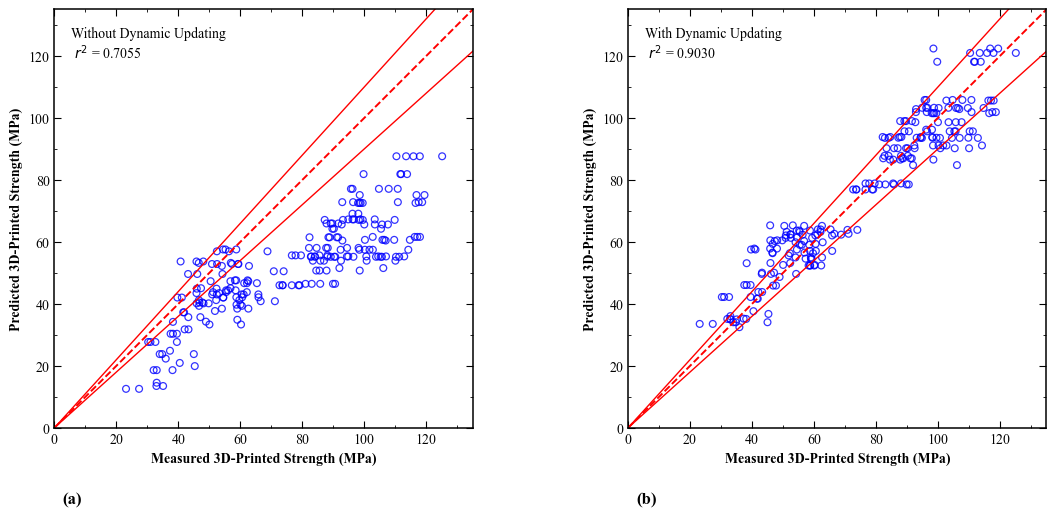

In [2]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.labelweight": "bold",
    "axes.linewidth": 1.1,
})

@torch.no_grad()
def fig8_predictions(weights):
    network = HeteroHierGNN(
        hidden_dim=pretrained_checkpoint["hidden_dim"],
        num_layers=pretrained_checkpoint["num_layers"],
        dropout=pretrained_checkpoint["dropout"],
    ).to(device)
    network.load_state_dict(weights, strict=True)
    network.eval()

    measured, predicted = [], []
    for batch in test_loader:  
        batch = batch.to(device)
        y_hat = inverse_scale_y(network(batch))
        measured.extend(batch["output"].y_raw.detach().cpu().numpy().ravel())
        predicted.extend(y_hat.detach().cpu().numpy().ravel())
    return np.asarray(measured), np.asarray(predicted)

updated_checkpoint = torch.load(updated_path, map_location="cpu", weights_only=True)
y_before, p_before = fig8_predictions(pretrained_checkpoint["model_state_dict"])
y_after, p_after = fig8_predictions(updated_checkpoint["model_state_dict"])
assert len(y_before) == len(y_after) == len(A_test_idx), "Test sample count differs."
assert np.array_equal(y_before, y_after), "Test records/order differ!"

lim = max(135, 5 * np.ceil(1.03 * np.max([y_before.max(), p_before.max(), p_after.max()]) / 5))
xx = np.linspace(0, lim, 300)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.25))
for ax, measured, predicted, heading, panel in zip(
    axes,
    [y_before, y_after],
    [p_before, p_after],
    ["Without Dynamic Updating", "With Dynamic Updating"],
    ["(a)", "(b)"],
):
    r2 = np.corrcoef(measured, predicted)[0, 1] ** 2
    ax.scatter(measured, predicted, s=24, facecolors="none",
               edgecolors="blue", linewidths=0.9, alpha=0.80)
    ax.plot(xx, xx, "r--", linewidth=1.4)       # 1:1 ideal
    ax.plot(xx, 1.1 * xx, "r-", linewidth=1.0) # +10%
    ax.plot(xx, 0.9 * xx, "r-", linewidth=1.0) # -10%
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Measured 3D-Printed Strength (MPa)", fontweight="bold")
    ax.set_ylabel("Predicted 3D-Printed Strength (MPa)", fontweight="bold")
    ax.text(0.04, 0.96, heading + "\n" + f" $r^2$ = {r2:.4f}",
            transform=ax.transAxes, va="top", fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
    ax.text(0.02, -0.18, panel, transform=ax.transAxes, fontweight="bold", fontsize=12)
    ax.tick_params(which="both", direction="in", top=True, right=True)
    ax.tick_params(which="major", length=5)
    ax.tick_params(which="minor", length=2.5)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

fig.tight_layout(w_pad=2)

print(f"Figure 8 — same {len(y_before)} held-out ASU samples in both panels")
print(f"Before: R² = {np.corrcoef(y_before, p_before)[0,1]**2:.4f}")
print(f"After : R² = {np.corrcoef(y_after, p_after)[0,1]**2:.4f}")

if input("Save Figure 8 and its plot data? (Y/N): ").strip().lower() == "y":
    os.makedirs("Graphs", exist_ok=True)
    fig.savefig("Graphs/Figure_8_Before_After_ASU.png", dpi=600,
                bbox_inches="tight", facecolor="white")
    pd.DataFrame({
        "ASU_cleaned_row_index": np.asarray(A_test_idx),
        "Measured_Strength_MPa": y_before,
        "Pretrained_Prediction_MPa": p_before,
        "Updated_Prediction_MPa": p_after,
    }).to_csv("Graphs/Figure_8_Plot_Data.csv", index=False)
    print("Saved PNG (600 dpi) and CSV in the Graphs folder.")

plt.show()


In [3]:
from importlib.metadata import version

packages = [
    "numpy",
    "pandas",
    "torch",
    "torch-geometric",
    "scikit-learn",
    "matplotlib",
    "openpyxl",
    "joblib",
]

requirements = []

for package in packages:
    try:
        requirements.append(
            f"{package}=={version(package)}"
        )
    except Exception:
        print(f"Could not determine version for {package}")

with open("requirements.txt", "w") as f:
    f.write("\n".join(requirements))

print("\n".join(requirements))


numpy==2.3.5
pandas==2.3.3
torch==2.11.0
torch-geometric==2.7.0
scikit-learn==1.7.2
matplotlib==3.10.6
openpyxl==3.1.5
joblib==1.5.2
